# 01 Exploratory data analysis (EDA): LCF 2013

**Goal of this notebook:** get to know the data before building any model.
We check its quality, look at the target (weekly household expenditure), and see which variables seem related to it.

How to use it: run one cell at a time (Shift+Enter) and read the output. Every section ends with a **Check yourself** question.
If you cannot answer it, re-run the cell above and change something to see what happens.

## Step 1. Import the tools

In [17]:
import pandas as pd              # tables (DataFrames)
import numpy as np               # maths helpers
import matplotlib.pyplot as plt  # plots
import seaborn as sns            # nicer plots (used once, for the heatmap)

# Folder where plots for the thesis are saved (PDF = sharp at any size)
FIG_DIR = "../reports/figures/"


## Step 2. Load the data
The file is a Stata file (`.dta`). pandas can read it directly. `convert_categoricals=False` keeps the codes as plain numbers (1, 2, 3...), which is what the models need.

In [18]:
df = pd.read_stata("../data/raw/icfforworkbook.dta", convert_categoricals=False)
print("rows, columns:", df.shape)
df.head()

rows, columns: (5144, 19)


,casenew,weighta,P550tpr,P344pr,P425r,A172,A093r,A094r,A121r,SexHRP,A049r,G018r,G019r,Gorx,weightar,maininc,income,expenditure,hhsize
0,14999,2.834724,380.695762,465.36,1,1,4,3,1,2,4,2,3,4,0.543248,0,465.359985,380.695770,4
1,14993,10.077947,546.413403,855.26,1,1,1,4,3,2,2,2,1,7,1.931344,0,855.260010,546.413391,2
2,14993,4.088676,242.189023,160.96,1,1,1,2,3,2,1,1,1,8,0.783557,0,160.960007,242.189026,1
3,14984,4.571760,421.382353,656.22,1,1,1,3,3,1,2,2,1,6,0.876135,0,656.219971,421.382355,2
4,14981,7.349617,370.405577,398.80,1,1,1,4,3,1,1,1,1,8,1.408485,0,398.799988,370.405579,1


**Check yourself:** how many households are in the data? How many columns? (The user guide says 5,144 and 19.)

The data has 5,144 rows, one per household, and 19 columns, one per variable. This matches the UKDS user guide, so the file loaded correctly.


## Step 3. What do the columns mean?
The full list is in the UKDS data dictionary. The ones we use most:

| Column | Meaning | Codes |
|---|---|---|
| `expenditure` | **Target.** Total weekly household spending, GBP | number |
| `income` | Gross normal weekly household income, GBP | number |
| `A094r` | Job class of the main person in the household (NS-SEC) | 1 = Higher managerial ... 5 = Not classified |
| `A121r` | Tenure (how the home is held) | 1 = Public rented, 2 = Private rented, 3 = Owned |
| `G018r` | Number of adults | 1, 2, 3, 4 (= 4 or more) |
| `G019r` | Number of children | 1 = none, 2 = one, 3 = two or more |
| `weightar` | Survey weight (average = 1) | number |

## Step 4. Remove duplicate columns
Some columns are copies of others (the dataset's second edition added renamed copies). We check that they really are identical before dropping them.

In [19]:
# np.allclose means "equal, apart from tiny rounding differences"
print("P550tpr is a copy of expenditure:", np.allclose(df["P550tpr"], df["expenditure"]))
print("P344pr  is a copy of income:     ", np.allclose(df["P344pr"], df["income"]))
print("A049r   is a copy of hhsize:     ", (df["A049r"] == df["hhsize"]).all())
print("P425r   is the same split as maininc (only the codes differ):")
print(pd.crosstab(df["P425r"], df["maininc"]))

P550tpr is a copy of expenditure: True
P344pr  is a copy of income:      True
A049r   is a copy of hhsize:      True
P425r   is the same split as maininc (only the codes differ):
maininc     0     1
P425r              
1        2841     0
2           0  2303


In [20]:
# casenew is a random ID, but some numbers repeat, so it cannot identify a household
print("repeated casenew values:", df["casenew"].duplicated().sum())

# Drop the copies, the useless ID, and the unscaled weight (weightar is the same weight, scaled)
df = df.drop(columns=["P550tpr", "P344pr", "A049r", "P425r", "casenew", "weighta"])
print("columns left:", df.shape[1])

repeated casenew values: 782
columns left: 13


**Check yourself:** why is it safe to drop `P550tpr`? Why not simply drop one column and trust the name?

Four columns were copies of others. I checked that the values matched in every row before dropping them, using np.allclose to allow for rounding. Trusting the names alone would be risky, because columns get renamed or recoded."


## Step 5. Data quality: missing values

In [21]:
print("missing values in the whole table:", df.isna().sum().sum())

missing values in the whole table: 0


## Step 6. The target: weekly expenditure

In [22]:
print(df["expenditure"].describe().round(1))
print()
print("mean   :", round(df["expenditure"].mean(), 1))
print("median :", round(df["expenditure"].median(), 1))
print("skewness:", round(df["expenditure"].skew(), 2))

count    5144.0
mean      479.8
std       292.4
min        30.5
25%       254.1
50%       419.9
75%       645.0
max      1175.0
Name: expenditure, dtype: float64

mean   : 479.8
median : 419.9
skewness: 0.83


Mean (about 480) is higher than the median (about 420) and the skewness is positive: a few households spend a lot, which pulls the mean up. This is called a **right-skewed** distribution. Let us look at it.

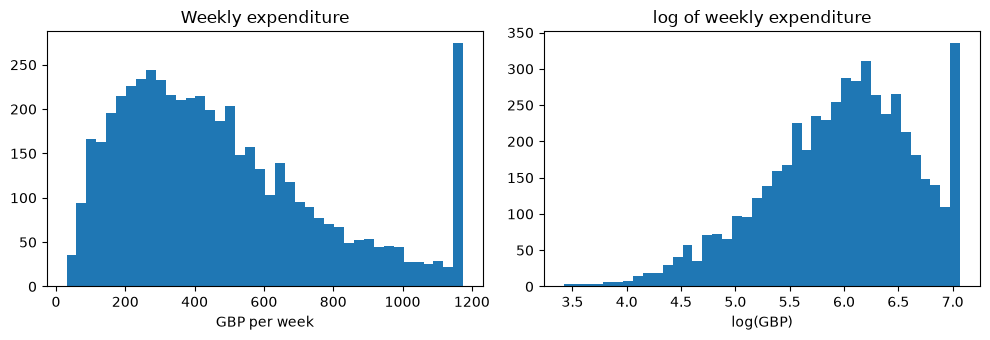

skewness after log: -0.53


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].hist(df["expenditure"], bins=40)
axes[0].set_title("Weekly expenditure")
axes[0].set_xlabel("GBP per week")

axes[1].hist(np.log(df["expenditure"]), bins=40)
axes[1].set_title("log of weekly expenditure")
axes[1].set_xlabel("log(GBP)")

plt.tight_layout()
plt.savefig(FIG_DIR + "target_distribution.pdf")
plt.show()
print("skewness after log:", round(np.log(df["expenditure"]).skew(), 2))

**Check yourself:** what does taking the log do to the shape? (We keep the raw target for the models, but this shows why a plain linear model may struggle with it.)

On the raw scale the distribution is right-skewed (a long tail on the right), with skewness 0.83. After taking the log, the right tail is pulled in (compressed) and the shape is more symmetric, but it overshoots slightly into a left tail, with skewness -0.53. The tall bar at the right end is the top-coded households.

## Step 7. Top-coding and outliers
The user guide says expenditure and income were *top-coded* at the 96th percentile: every value above the cap was replaced by the cap, to protect privacy.

In [24]:
max_exp = df["expenditure"].max()
max_inc = df["income"].max()

print("highest expenditure:", max_exp, "-> households at that value:", (df["expenditure"] == max_exp).sum())
print("highest income:     ", round(max_inc, 2), "-> households at that value:", (df["income"] > max_inc - 0.01).sum())
print("households with zero income:", (df["income"] == 0).sum())

highest expenditure: 1175.0 -> households at that value: 256
highest income:      1184.99 -> households at that value: 785
households with zero income: 12


In [25]:
# The usual "outlier rule": anything above Q3 + 1.5 * IQR
q1 = df["expenditure"].quantile(0.25)
q3 = df["expenditure"].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

print("upper fence:", round(upper_fence, 1))
print("households above it:", (df["expenditure"] > upper_fence).sum())

upper fence: 1231.2
households above it: 0


No household is above the fence because the top values were already cut at 1,175. So the *real* outliers are hidden by the top-coding. We do not remove anything; we simply **state this as a limitation** in the thesis.

**Check yourself:** why can we not fix top-coding by collecting the true values?

The true values are not in our file because the data provider capped them to protect household privacy. The original unrestricted survey (SN 7702) needs a separate application and approval and may not be available to me, and the households are anonymous in the dataset, so I cannot go back and ask them. So I cannot fix the top-coding, and instead I state it as a limitation in the thesis.

## Step 8. Expenditure by group (the four predictors from the earlier ANOVA)

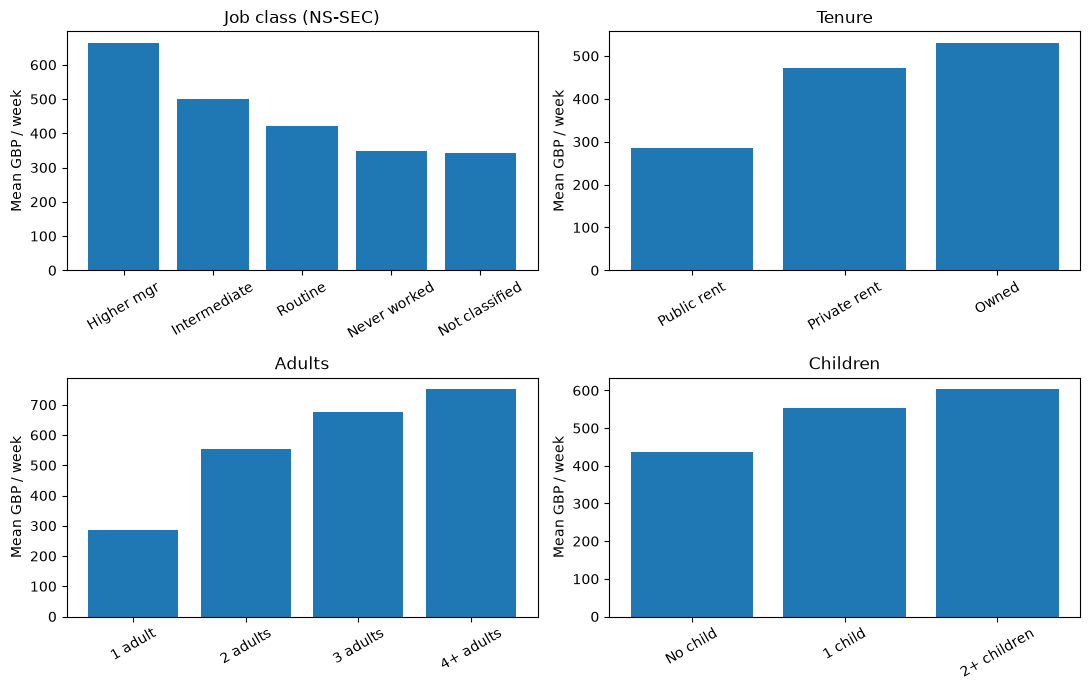

In [26]:
# Readable names for the codes
labels = {
    "A094r": {1: "Higher mgr", 2: "Intermediate", 3: "Routine", 4: "Never worked", 5: "Not classified"},
    "A121r": {1: "Public rent", 2: "Private rent", 3: "Owned"},
    "G018r": {1: "1 adult", 2: "2 adults", 3: "3 adults", 4: "4+ adults"},
    "G019r": {1: "No child", 2: "1 child", 3: "2+ children"},
}
titles = {"A094r": "Job class (NS-SEC)", "A121r": "Tenure", "G018r": "Adults", "G019r": "Children"}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes = axes.ravel()

for ax, col in zip(axes, labels):
    means = df.groupby(col)["expenditure"].mean()           # average spending per group
    ax.bar([labels[col][k] for k in means.index], means.values)
    ax.set_title(titles[col])
    ax.set_ylabel("Mean GBP / week")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig(FIG_DIR + "expenditure_by_group.pdf")
plt.show()

**Check yourself:** which variable shows the biggest differences between its groups? Does this match what you found in the ANOVA?

The largest difference between groups is in the number of adults: average weekly spending goes from about £285 for one adult to about £750 for four or more adults. The next largest is job class (about £345 to £665), then tenure, and the smallest is children. This matches my ANOVA, where number of adults ranked first (η² = 0.248), followed by occupational class (0.209), tenure (0.097) and children (0.055).


## Step 9. Income and expenditure

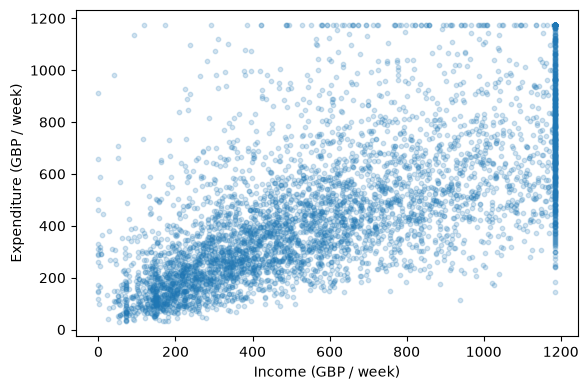

correlation: 0.71


In [27]:
plt.figure(figsize=(6, 4))
plt.scatter(df["income"], df["expenditure"], alpha=0.2, s=10)
plt.xlabel("Income (GBP / week)")
plt.ylabel("Expenditure (GBP / week)")
plt.tight_layout()
plt.savefig(FIG_DIR + "income_vs_expenditure.pdf")
plt.show()

print("correlation:", round(df["income"].corr(df["expenditure"]), 2))

The correlation is about 0.71, a strong positive relationship. The earlier ANOVA did not use income, which is why we will test **two settings** later: the four ANOVA variables only (Setting A) and all variables including income (Setting B).

## Step 10. Which variables relate to expenditure?

In [28]:
# Correlation of every column with expenditure (codes treated as numbers, so this is only a rough guide)
print(df.corr()["expenditure"].drop("expenditure").sort_values().round(2))

A094r      -0.44
A093r      -0.40
maininc    -0.40
A172       -0.39
SexHRP     -0.21
weightar    0.03
Gorx        0.08
G019r       0.23
A121r       0.30
hhsize      0.45
G018r       0.47
income      0.71
Name: expenditure, dtype: float64


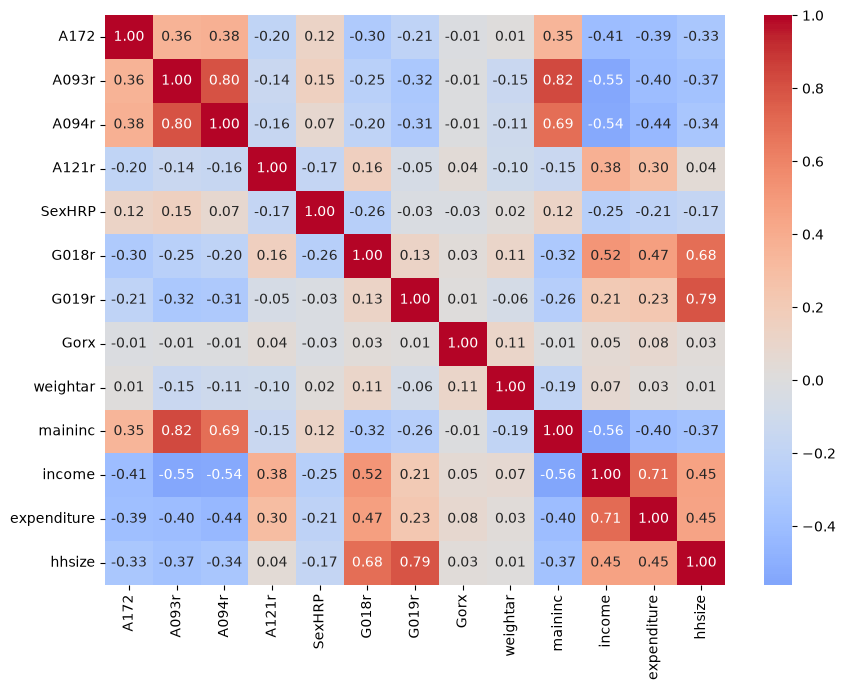

In [29]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.tight_layout()
plt.savefig(FIG_DIR + "correlation_matrix.pdf")
plt.show()

**Check yourself:** `hhsize` and `G018r` are strongly correlated with each other. Why might that cause trouble for a linear model?

hhsize is correlated with G018r (0.68) and G019r (0.79) because household size is roughly adults plus children, so it repeats their information. In a linear model this makes the coefficients unstable and hard to interpret, because the model cannot tell which variable is responsible for the effect. The predictions may still be fine, but the interpretation of each variable is not. Tree-based models like Random Forest are less affected.


## Step 11. Classification target: three spending groups
For the classification task we cut expenditure into three equal-sized groups (**tertiles**): Low, Mid, High.

In [13]:
df["segment"] = pd.qcut(df["expenditure"], 3, labels=["Low", "Mid", "High"])

print(df["segment"].value_counts())
print()
print(df.groupby("segment", observed=True)["expenditure"].agg(["min", "max", "mean"]).round(1))

segment
Low     1715
High    1715
Mid     1714
Name: count, dtype: int64

                min          max        mean
segment                                     
Low       30.500000   306.000000  194.300003
Mid      306.000000   551.299988  421.700012
High     551.400024  1175.000000  823.299988


The three groups are almost exactly equal in size, so plain accuracy is a fair metric.

*Note for the models later:* here we cut on the whole sample just to look at the groups. In the real experiments the cut points are calculated on the **training data only**, so that no information from the test data leaks in.

## Step 12. Survey weights

In [14]:
print(df["weightar"].describe().round(2))
print("households with weight above 3:", (df["weightar"] > 3).sum())

count    5144.00
mean        1.00
std         0.34
min         0.00
25%         0.78
50%         0.94
75%         1.14
max         4.70
Name: weightar, dtype: float64
households with weight above 3: 12


The weight tells us how many households in the population each surveyed household represents. Most are near 1, but a few are very large or very small. We will run the main analysis **unweighted** (as in the ANOVA) and use the weights only as a **sensitivity check**.

## Step 13. Your own summary (write this in your own words)

Answer in 5 to 8 sentences. This goes into your thesis notes and later into Chapter 4.

1. What does the data look like (size, quality, target distribution)?
2. What limitations did you find (top-coding, coarse categories, duplicates)?
3. Which variables look most related to expenditure, and does that agree with the ANOVA?
4. What would you do differently if you could collect the data yourself?



1. There are 5,144 households and 19 variables (13 after removing duplicates and unusable columns), with no missing values. Weekly household expenditure is right-skewed (skewness 0.83), with a few households spending much more than most. The log makes it more symmetric (-0.53).

2. Top-coding: expenditure is capped at £1,175 (256 households) and income at £1,185 (785 households). The extreme values are hidden, so models cannot learn about the very highest spenders. There are four duplicate columns, and casenew is not a unique ID. There is no spending breakdown by category, so I can predict total spending but not what it is spent on, and there is no equivalence scale.

3. Income is the strongest single predictor of expenditure, with r = 0.71. Among the four ANOVA variables, the order is adults, then job class, then tenure, then children. This matches the ANOVA's η² order (0.248, 0.209, 0.097, 0.055). Tenure looks stronger in the chart than it is: owners are mostly higher-class households, so its effect drops 59% in the combined model once job class is included.

4. I would add spending broken down by category, so I could predict spending on food or housing. The data is from 2013, so I would also try to get more recent data to check whether the relationships found in 2013 still hold.